## Linear Model
The first thing we wish to try is if we can fit a linear model to this data. We do this since it would be the simplest explanation of the data and would be convenient for analysis. In practice this is not often a good fit but we wanted to try fitting it just in case. We will then check if the linear model looks to be a good fit, before looking at if we can improve on AIC by using two types of feature selection, LASSO and Principal Component Analysis.

We start by importing the data into the notebook that we produced in 1_Splitting_Data.ipynb

In [1]:
# Importing all the libraries we will use in this section
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import numpy as np
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error

train_data = pd.read_csv("attainment8_train.csv") # Importing the two datasets we will be using 
test_data = pd.read_csv("attainment8_test.csv")

In [2]:
covariates = ['attainment8_average','time_period', 'la_name', # Creating a list of all of the covariates that we are interested in
       'establishment_type_group', 'pcon_name',
       'school_admission_type', 'school_religious_character_detailed',
       'sex_policy', 'min_age', 'max_age', 'allks_pupil_count',
       'endks4_pupil_count',
       'sen_pupil_count', 'sen_pupil_percent', 'sen_with_ehcp_pupil_count',
       'sen_with_ehcp_pupil_percent', 'sen_no_ehcp_pupil_count',
       'sen_no_ehcp_pupil_percent', 'pupil_count',
       'gcse_entries_average', 'qual_entries_average',
       'sci_triple_entering_percent', 'lan_multiple_entering_percent',
       'ks4_disadvantaged_pupil_count', 'ks4_disadvantaged_pupil_percent',
       'ks4_not_known_disadvantaged_pupil_count',
       'ks4_not_known_disadvantaged_pupil_percent',
       'ks4_first_language_other_than_english_pupil_count',
       'ks4_first_language_other_than_english_pupil_percent',
       'ks4_non_mobile_pupil_count', 'ks4_non_mobile_pupil_percent']

df = pd.get_dummies( # Here we split the categorical covariates up into binary covariates 
    train_data[covariates],
    drop_first=True,
    dtype=int
)

df.head()

,attainment8_average,time_period,min_age,max_age,allks_pupil_count,endks4_pupil_count,sen_pupil_count,sen_pupil_percent,sen_with_ehcp_pupil_count,sen_with_ehcp_pupil_percent,...,school_religious_character_detailed_Hindu,school_religious_character_detailed_Jewish,school_religious_character_detailed_Multi-faith,school_religious_character_detailed_Muslim,school_religious_character_detailed_Roman Catholic,school_religious_character_detailed_Roman Catholic/Church of England,school_religious_character_detailed_Sikh,sex_policy_Gender unclassified,sex_policy_Girls,sex_policy_Mixed
0,50.9,202526,11,16,917.0,178.0,25.0,14.0,7.0,3.9,...,0,0,0,0,0,0,0,0,0,1
1,43.5,202526,13,19,781.0,181.0,46.0,25.4,9.0,5.0,...,0,0,0,0,0,0,0,0,0,1
2,47.4,202324,11,16,893.0,184.0,40.0,21.7,4.0,2.2,...,0,0,0,0,0,0,0,0,0,1
3,42.7,202324,11,18,1105.0,205.0,32.0,15.6,4.0,2.0,...,0,0,0,0,1,0,0,0,0,1
4,44.0,202425,11,16,1029.0,203.0,41.0,20.2,15.0,7.4,...,0,0,0,0,0,0,0,0,0,1


In [3]:
print(df.columns) # Doing this to check that the data looks correct
print(df.info())

Index(['attainment8_average', 'time_period', 'min_age', 'max_age',
       'allks_pupil_count', 'endks4_pupil_count', 'sen_pupil_count',
       'sen_pupil_percent', 'sen_with_ehcp_pupil_count',
       'sen_with_ehcp_pupil_percent',
       ...
       'school_religious_character_detailed_Hindu',
       'school_religious_character_detailed_Jewish',
       'school_religious_character_detailed_Multi-faith',
       'school_religious_character_detailed_Muslim',
       'school_religious_character_detailed_Roman Catholic',
       'school_religious_character_detailed_Roman Catholic/Church of England',
       'school_religious_character_detailed_Sikh',
       'sex_policy_Gender unclassified', 'sex_policy_Girls',
       'sex_policy_Mixed'],
      dtype='object', length=755)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7873 entries, 0 to 7872
Columns: 755 entries, attainment8_average to sex_policy_Mixed
dtypes: float64(22), int64(733)
memory usage: 45.4 MB
None


### Fitting the model
We now separate the target variable, attainment8_average, from the covariates, which we call X. We then fit the full linear model, using all available covariates.

We found a website called geeksforgeeks (https://www.geeksforgeeks.org/python/linear-regression-in-python-using-statsmodels/) in sprint 0 that discussed how to use statsmodels.api to fit linear models to our data and used it again here.

In [4]:
# Separate the target variable from the explanatory variables
y = df['attainment8_average']
X = df.drop(columns=['attainment8_average'])

X = sm.add_constant(X) # Adds a constant for the intercept

full_linear_model = sm.OLS(y, X).fit() # Fits the linear regression model

print(full_linear_model.summary()) # Displays the results

                             OLS Regression Results                            
Dep. Variable:     attainment8_average   R-squared:                       0.865
Model:                             OLS   Adj. R-squared:                  0.851
Method:                  Least Squares   F-statistic:                     66.12
Date:                 Sat, 31 Oct 2026   Prob (F-statistic):               0.00
Time:                         16:59:16   Log-Likelihood:                -20961.
No. Observations:                 7873   AIC:                         4.331e+04
Df Residuals:                     7179   BIC:                         4.815e+04
Df Model:                          693                                         
Covariance Type:             nonrobust                                         
                                                                            coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------

We now take a look at how well this model predicts the test data. To do this, we first need to do the same data preparation that we've done on the training data so far.

In [5]:
test_df = pd.get_dummies( # Here we split the categorical covariates up into binary covariates 
    test_data[covariates],
    drop_first=True,
    dtype=int
)

# test_df = test_df.reindex(columns=df.columns, fill_value=0) 

# Separate the target variable from the explanatory variables
y_test = test_df['attainment8_average'] 
X_test_raw = test_df.drop(columns=['attainment8_average'])

X_test = sm.add_constant(X_test_raw, has_constant='add') # Adds a constant for the intercept

X_test = X_test.reindex(columns=X.columns, fill_value=0) # Matches up the test columns to the training columns

print("Number of test observations:", len(y_test)) # We check that the test data is how we expect it to look
print("Number of test predictors:", X_test_raw.shape[1])

Number of test observations: 1969
Number of test predictors: 754


In [6]:
full_predictions = full_linear_model.predict(X_test) # Predicts the attainment8_average scores for the test data

full_rmse = np.sqrt(
    mean_squared_error(y_test, full_predictions) # Calculate test RMSE between the data and the predictions
)

print("Full linear regression test RMSE:", full_rmse)

Full linear regression test RMSE: 3.8776753532109227


### Feature Selection: LASSO
Currently our model has a very high number of features, so we will now try and improve upon our models by reducing complexity through feature selection. Due to the computational costs, it is impractical to repeat the use of the stepwise selection function we defined in sprint 0, so instead we will try some other methods of feature selection. 

The first method of doing this will be using LASSO to select features. LASSO works by adding a penalty on the absolute values of the regression coefficients. It aims to minimises the function

$$
\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
+\lambda\sum_{j=1}^{p}|\beta_j|,
$$

where $y_i$ and $\hat{y}_i$ are the observed and predicted values, $\beta_j$ are the regression coefficients, and $\lambda \geq 0$ controls the strength of the penalty. As $\lambda$ increases, coefficients are increasingly shrunk towards zero, with some becoming exactly zero. The features with coefficients equal to 0 are therefore excluded from the model, allowing LASSO to perform feature selection. Here, we use cross-validation to select the penalty strength, and predictors with non-zero coefficients are retained for the subsequent regression model.

We start, as we did before, by separating the target variable from the potential features.

In [10]:
# Separate the target from the explanatory variables
y_lasso = df['attainment8_average']

X_lasso = df.drop(
    columns=['attainment8_average']
)

We now try to find the value of $\lambda$ that gives us the best cross validation results.

In [11]:
# Create a pipeline that standardises predictors before fitting LASSO
pipeline = Pipeline([
    ('scaler', StandardScaler()), # StandardScaler puts predictors on a comparable scale, so variables with larger numerical values are not unfairly penalised
    ('lasso', Lasso(max_iter=20000)) # Allows up to 20,000 iterations for convergence
])

# Tests a range of values for lambda
param_grid = {
    'lasso__alpha': np.logspace(-3, 3, 100)
}

cv = KFold(n_splits=5, shuffle=True, random_state=42) # Sets up the five-fold cross-validation we will use to find lambda

lasso_search = GridSearchCV( # Compares the candidate alpha values.
    estimator=pipeline,
    param_grid=param_grid,
    scoring='neg_mean_squared_error', # this is used because scikit-learn maximises scores negating the MSE allows the search to identify the lowest MSE
    cv=cv,
    n_jobs=-1 # this allows all available CPU cores to be used
)

lasso_search.fit(X_lasso, y_lasso) # Fits the grid search using the training predictors and target

print("Best penalty:", lasso_search.best_params_['lasso__alpha']) # Prints the best lambda value

Best penalty: 0.0093260334688322
Best cross-validated RMSE: 3.8032803412969804


Now we take the value of $\lambda$ that we have decided on and use it to select the features we want to use.

In [12]:
lasso_fitted = lasso_search.best_estimator_.named_steps['lasso'] # Extracts the fitted LASSO model

coefficients = pd.Series( # Associates each LASSO coefficient with its original predictor
    lasso_fitted.coef_, # Gets the coefficient for each predictor
    index=X_lasso.columns # Labels each coefficient with its predictor name
)

selected_features = coefficients[coefficients != 0] # Keeps only predictors with non-zero coefficients

print("Original number of predictors:", X_lasso.shape[1])
print("Number of predictors selected:", len(selected_features))

print("\nSelected predictors:")
print(
    selected_features 
    .sort_values(key=abs, ascending=False) # Shows us the remaining features after LASSO selection
)

Original number of predictors: 754
Number of predictors selected: 586

Selected predictors:
school_admission_type_Selective schools    2.736483
ks4_disadvantaged_pupil_percent           -2.710569
allks_pupil_count                          1.895838
qual_entries_average                       1.444162
gcse_entries_average                       1.174461
                                             ...   
pcon_name_Normanton and Hemsworth          0.000837
pcon_name_Goole and Pocklington           -0.000785
pcon_name_North Durham                     0.000553
pcon_name_Birmingham Selly Oak             0.000414
pupil_count                               -0.000033
Length: 586, dtype: float64


So our LASSO selection has worked and removed over a hundred features. Now we will fit a model with these remaining features and see if it's any better than the full model.

In [13]:
X_selected = X_lasso[selected_features.index] # Selects the predictors retained by LASSO

X_selected = sm.add_constant(X_selected) # Adds an intercept

lasso_selected_linear_model = sm.OLS(y_lasso, X_selected).fit() # Fits a linear model


print(lasso_selected_linear_model.summary())

                             OLS Regression Results                            
Dep. Variable:     attainment8_average   R-squared:                       0.864
Model:                             OLS   Adj. R-squared:                  0.853
Method:                  Least Squares   F-statistic:                     79.13
Date:                 Sat, 31 Oct 2026   Prob (F-statistic):               0.00
Time:                         17:15:02   Log-Likelihood:                -20983.
No. Observations:                 7873   AIC:                         4.314e+04
Df Residuals:                     7288   BIC:                         4.721e+04
Df Model:                          584                                         
Covariance Type:             nonrobust                                         
                                                                           coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------

This is a promising result, both the adjusted R-squared and the AIC have improved in this model when compared to the full model. Now we will use the test data to compare the RMSE to the full linear model.

In [14]:
#X_test_lasso = X_test_raw.reindex( # Matches the test predictors to those used by the original LASSO
 #   columns=X_lasso.columns,
  #  fill_value=0
#)

X_test_selected = X_test_lasso[selected_features.index] # Keeps only the predictors selected by LASSO

X_test_selected = sm.add_constant( # Adds the intercept
    X_test_selected,
    has_constant='add'
)

X_test_selected = X_test_selected.reindex( # Matches the test predictors to those used by the original LASSO
    columns=X_selected.columns,
    fill_value=0
)

lasso_selected_predictions = lasso_selected_linear_model.predict( # Predicts attainment8_average scores
    X_test_selected
)

lasso_selected_rmse = np.sqrt( 
    mean_squared_error(y_test, lasso_selected_predictions) # Calculates test RMSE
)

print("LASSO-selected linear regression test RMSE:",
      lasso_selected_rmse)

LASSO-selected linear regression test RMSE: 3.8561642087631913


So the LASSO selected model improves on the root mean squared error from the linear model fitted with all the potential features. So this should be our preferred model so far. We will now try an alternative feature selection system and see if we can improve upon the LASSO selected model.

### Feature Selection: Principal Component Analysis
The second method we will use for feature selection is principal component analysis. Principal component analysis (PCA) reduces the number of variables by combining the original predictors into a smaller set of 'principal components'. The components are formed from linear combinations of the original predictors and are ordered by how much of the variation in the data they explain. PCA retains enough components to explain a chosen proportion of the variance, this reduces the dimensionality of the data while preserving as much information as possible. Unlike LASSO, PCA does not select individual features from the original variable, it creates new components from combinations of the original variables.

In [15]:
# Create a PCA pipeline
pca_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=0.95))
])

# Fit PCA using training predictors ONLY
X_pca = pca_pipeline.fit_transform(X_lasso)

# Report the reduction in dimensionality
print("Original number of predictors:", X_lasso.shape[1])
print("Number of principal components:", X_pca.shape[1])

print(
    "Proportion of variance explained:",
    pca_pipeline.named_steps['pca'].explained_variance_ratio_.sum()
)

# Add an intercept
X_pca_const = sm.add_constant(X_pca, has_constant='add')

# Fit the regression model using the training target
pca_linear_model = sm.OLS(y_lasso, X_pca_const).fit()

print(pca_linear_model.summary())

Original number of predictors: 754
Number of principal components: 504
Proportion of variance explained: 0.9004259275959208
                             OLS Regression Results                            
Dep. Variable:     attainment8_average   R-squared:                       0.820
Model:                             OLS   Adj. R-squared:                  0.808
Method:                  Least Squares   F-statistic:                     66.55
Date:                 Sat, 31 Oct 2026   Prob (F-statistic):               0.00
Time:                         17:15:05   Log-Likelihood:                -22082.
No. Observations:                 7873   AIC:                         4.517e+04
Df Residuals:                     7368   BIC:                         4.869e+04
Df Model:                          504                                         
Covariance Type:             nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.97

In [16]:
# Transform the test predictors using the PCA fitted on the training data
X_test_pca = pca_pipeline.transform(X_test_lasso)

# Add the intercept
X_test_pca_const = sm.add_constant(
    X_test_pca,
    has_constant='add'
)

# Predict attainment scores
pca_predictions = pca_linear_model.predict(X_test_pca_const)

# Calculate test RMSE
pca_rmse = np.sqrt(
    mean_squared_error(y_test, pca_predictions)
)

print("PCA regression test RMSE:", pca_rmse)

PCA regression test RMSE: 4.3206475670513065


### Is the linear model good for our data?
Now we assess if our linear model might actually be a good way of modelling our data. There are 4 assumptions in a linear model: 

(i) the regression function is linear, 

(ii) the errors have zero mean and constant variance 

(iii) the errors are independent 

(iv) the errors are normally distributed. 

Thankfully, there are some standard plots we can produce that can tell us whether these are fair assumptions, which we produce below. 

We found information on how to code these with statsmodels.api on the statsmodels website (https://www.statsmodels.org/stable/examples/notebooks/generated/linear_regression_diagnostics_plots.html) and adapted it for our dataset. 

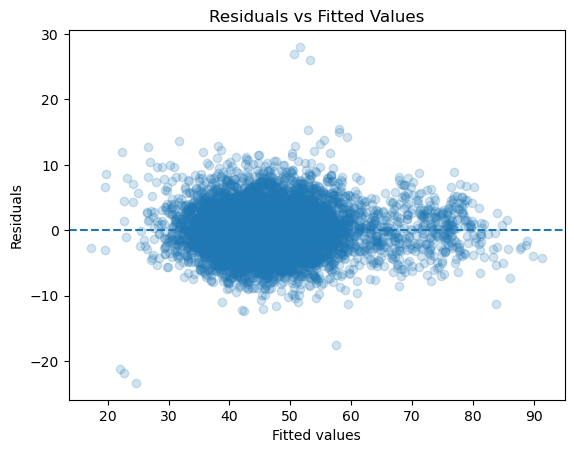

In [7]:
# Extracts fitted values and residuals
fitted_values = full_linear_model.fittedvalues
residuals = full_linear_model.resid

# Plots residuals against fitted values
plt.scatter(fitted_values, residuals, alpha=0.2) # We make alpha 0.2 to better see the density of how points are distributed

# Adds a horizontal line at zero
plt.axhline(y=0, linestyle="--")

plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted Values")

plt.show()

There is a slight skew to the left in this plot, meaning the data could violate the linearity assumption of the linear model.

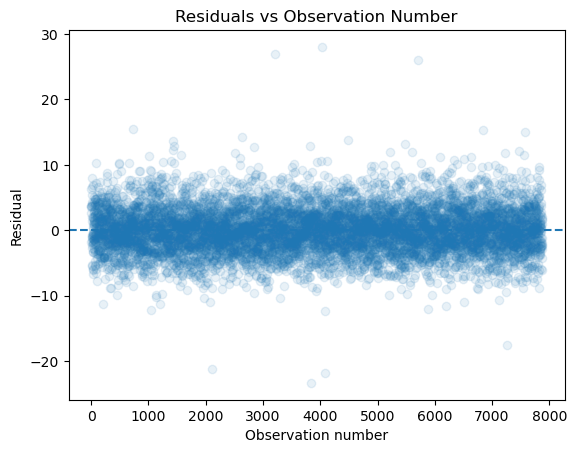

In [8]:
# Creates observation numbers: 1, 2, ..., n
observation_number = range(1, len(residuals) + 1)

plt.scatter(observation_number, residuals, alpha=0.1)

# Adds a horizontal line at zero
plt.axhline(y=0, linestyle="--")

plt.xlabel("Observation number")
plt.ylabel("Residual")
plt.title("Residuals vs Observation Number")

plt.show()

This plot suggests that the data likely doesn't violate the indepence of observations assumption.

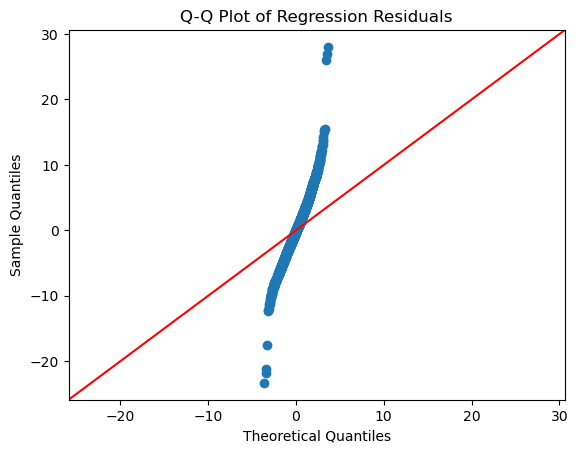

In [9]:
sm.qqplot(residuals, line="45") # Makes a Q-Q plot

plt.title("Q-Q Plot of Regression Residuals")

plt.show()

This plot suggests that there is are heavy tails, and the normality assumption of the linear model is violated.

This time, at least two of the assumptions for a linear model have been violated, linearity and normality. This does mean that this linear model is not a good way of modelling the data.

We now produce some plots of some individual columns vs attainment8_average to see if their relations are linear.

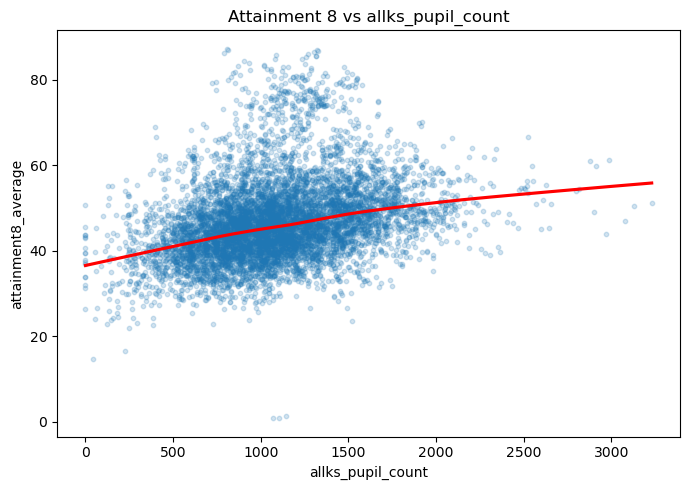

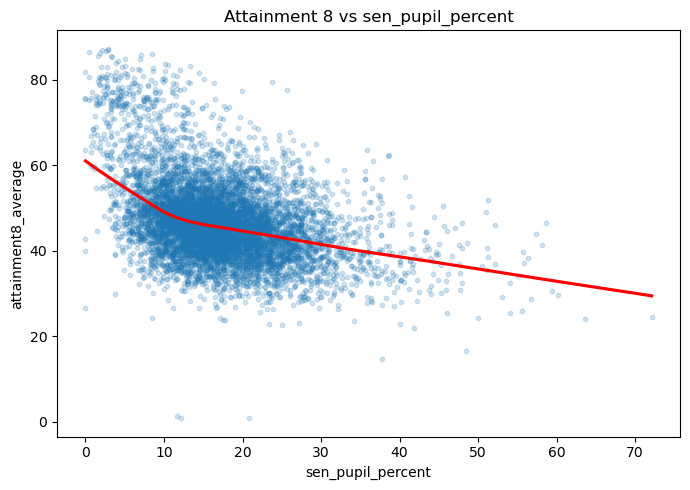

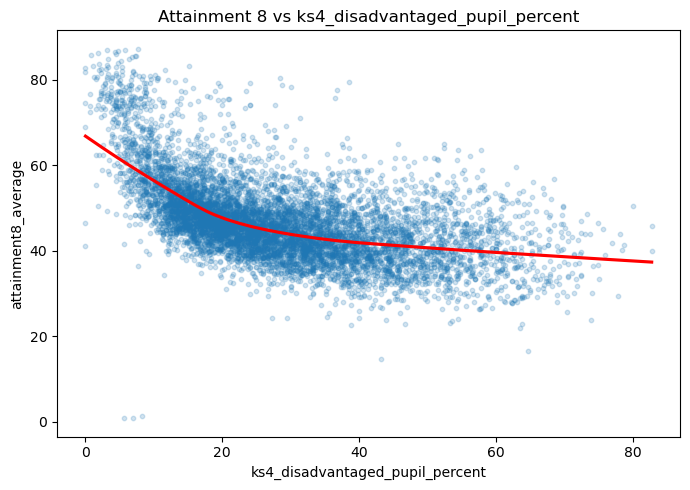

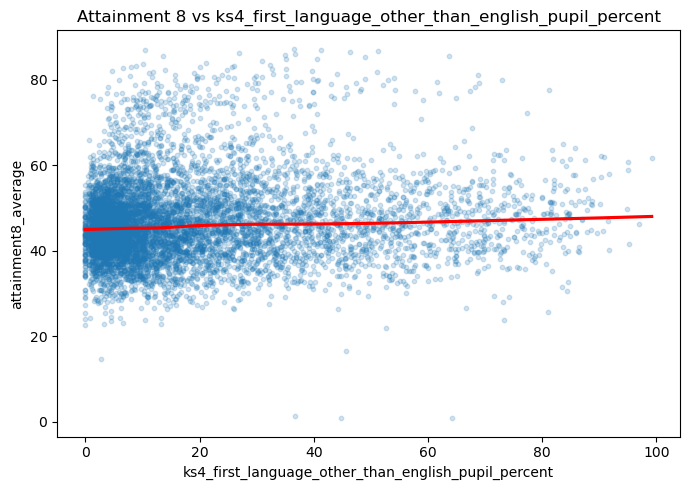

In [17]:
plot_variables = [
    'allks_pupil_count',
    'sen_pupil_percent',
    'ks4_disadvantaged_pupil_percent',
    'ks4_first_language_other_than_english_pupil_percent', 
]

# Combine your chosen predictors with the outcome
plot_data = df[
    ['attainment8_average'] + plot_variables
].copy()

# Plot each covariate against Attainment 8
for variable in plot_variables:
    plt.figure(figsize=(7, 5))

    sns.regplot(
        data=plot_data,
        x=variable,
        y='attainment8_average',
        lowess=True,
        scatter_kws={'alpha': 0.2, 's': 10},
        line_kws={'color': 'red'}
    )

    plt.title(f'Attainment 8 vs {variable}')
    plt.tight_layout()
    plt.show()

Most of the relationships in these graphs do not look linear at all, so we could try transforming some of the columns and see if we can then produce a better model.

Before trying that we also produce some other potentially interesting plots.

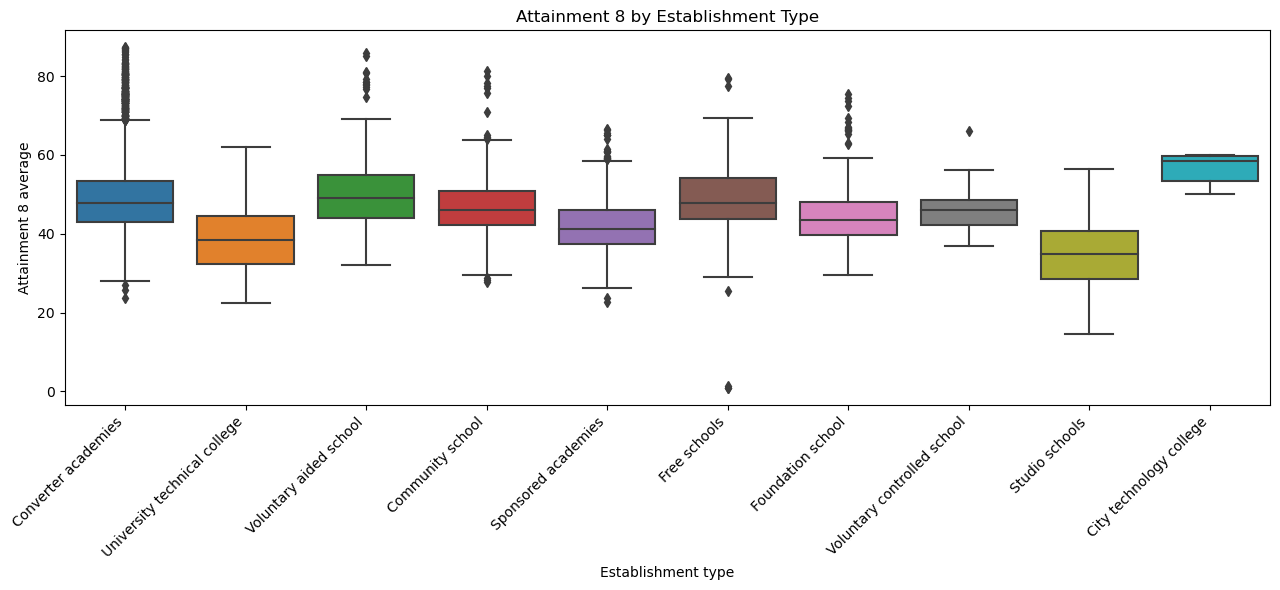

In [18]:
# Plot the distribution of attainment scores by establishment type
plt.figure(figsize=(13, 6))

sns.boxplot(
    data=train_data,
    x='establishment_type_group',
    y='attainment8_average'
)

plt.xticks(rotation=45, ha='right')
plt.xlabel('Establishment type')
plt.ylabel('Attainment 8 average')
plt.title('Attainment 8 by Establishment Type')

plt.tight_layout()
plt.show()

In [19]:
# Begin with all original predictors
X_transformed = X.copy()

# Track which transformations have been generated
transformation_names = []

for col in X.columns:

    # Don't transform binary variables, such as dummy variables
    if X[col].nunique() <= 2:
        continue

    # Quadratic transformation
    new_name = f'{col}_squared'
    X_transformed[new_name] = X[col] ** 2
    transformation_names.append(new_name)

    # Logarithmic transformation, for non-negative variables
    if (X[col] >= 0).all():
        new_name = f'{col}_log'
        X_transformed[new_name] = np.log1p(X[col])
        transformation_names.append(new_name)

    # Reciprocal transformation, for strictly positive variables
    if (X[col] > 0).all():
        new_name = f'{col}_reciprocal'
        X_transformed[new_name] = 1 / X[col]
        transformation_names.append(new_name)

print(f'Original predictors: {X.shape[1]}')
print(f'Additional transformations: {len(transformation_names)}')
print(f'Total candidate predictors: {X_transformed.shape[1]}')

Original predictors: 755
Additional transformations: 56
Total candidate predictors: 811


In [22]:
# Add a constant for the intercept
X_transformed = sm.add_constant(X_transformed)

# Fit the linear regression model
full_transformed_model = sm.OLS(y, X_transformed).fit()

# Display the results
print(full_transformed_model.summary())

                             OLS Regression Results                            
Dep. Variable:     attainment8_average   R-squared:                       0.881
Model:                             OLS   Adj. R-squared:                  0.869
Method:                  Least Squares   F-statistic:                     74.11
Date:                 Sat, 31 Oct 2026   Prob (F-statistic):               0.00
Time:                         17:19:35   Log-Likelihood:                -20445.
No. Observations:                 7873   AIC:                         4.232e+04
Df Residuals:                     7156   BIC:                         4.732e+04
Df Model:                          716                                         
Covariance Type:             nonrobust                                         
                                                                            coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------

In [23]:
# Prepare the test predictors using the same transformations as the training data
X_test_transformed = X_test.copy()

for col in X.columns:
    if X[col].nunique() <= 2:
        continue

    # Squared transformation
    X_test_transformed[f'{col}_squared'] = X_test_transformed[col] ** 2

    # Log transformation (only if all training values were non-negative)
    if (X[col] >= 0).all():
        X_test_transformed[f'{col}_log'] = np.log1p(X_test_transformed[col])

    # Reciprocal transformation (only if all training values were positive)
    if (X[col] > 0).all():
        if (X_test_transformed[col] == 0).any():
            raise ValueError(
                f"Cannot calculate reciprocal transformation for {col}: "
                "test data contains zero values."
            )
        X_test_transformed[f'{col}_reciprocal'] = (
            1 / X_test_transformed[col]
        )

# Match the training model's predictor columns and order
X_test_transformed = X_test_transformed.reindex(
    columns=X_transformed.columns,
    fill_value=0
)

# Predict attainment scores for the test data
transformed_full_predictions = full_transformed_model.predict(
    X_test_transformed
)

# Calculate test RMSE
transformed_full_rmse = np.sqrt(
    mean_squared_error(y_test, transformed_full_predictions)
)

print("Full transformed linear regression test RMSE:", transformed_full_rmse)

Full transformed linear regression test RMSE: 3.665427091669799


In [24]:
# Create a PCA pipeline using the transformed predictors
pca_transformed_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=0.90))
])

# Fit PCA using the transformed predictors only
X_transformed_pca = pca_transformed_pipeline.fit_transform(
    X_transformed.drop(columns=['const'], errors='ignore')
)

# Display how many components PCA retained
print("Number of transformed predictors:",
      X_transformed.drop(columns=['const'], errors='ignore').shape[1])

print("Number of principal components:",
      X_transformed_pca.shape[1])

print("Proportion of variance explained:",
      pca_transformed_pipeline.named_steps['pca']
      .explained_variance_ratio_.sum())

Number of transformed predictors: 810
Number of principal components: 506
Proportion of variance explained: 0.9007404019150633


In [25]:
# Add a constant for the intercept
X_transformed_pca_const = sm.add_constant(
    X_transformed_pca,
    has_constant='add'
)

# Fit the linear regression model
pca_transformed_model = sm.OLS(
    y,
    X_transformed_pca_const
).fit()

# Display the results
print(pca_transformed_model.summary())

                             OLS Regression Results                            
Dep. Variable:     attainment8_average   R-squared:                       0.828
Model:                             OLS   Adj. R-squared:                  0.816
Method:                  Least Squares   F-statistic:                     69.84
Date:                 Sat, 31 Oct 2026   Prob (F-statistic):               0.00
Time:                         17:24:40   Log-Likelihood:                -21912.
No. Observations:                 7873   AIC:                         4.484e+04
Df Residuals:                     7366   BIC:                         4.837e+04
Df Model:                          506                                         
Covariance Type:             nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         46.9193      0.046   1029.11

In [26]:
# Remove the constant column before applying PCA
X_test_transformed_predictors = X_test_transformed.drop(
    columns=['const'],
    errors='ignore'
)

# Ensure test columns match the transformed training predictors
X_test_transformed_predictors = (
    X_test_transformed_predictors.reindex(
        columns=X_transformed.drop(
            columns=['const'],
            errors='ignore'
        ).columns,
        fill_value=0
    )
)

# Apply the fitted scaler and PCA to the test data
X_test_transformed_pca = pca_transformed_pipeline.transform(
    X_test_transformed_predictors
)

# Add a constant for the intercept
X_test_transformed_pca_const = sm.add_constant(
    X_test_transformed_pca,
    has_constant='add'
)

In [27]:
# Predict attainment scores using the test data
pca_transformed_predictions = pca_transformed_model.predict(
    X_test_transformed_pca_const
)

# Calculate test RMSE
pca_transformed_rmse = np.sqrt(
    mean_squared_error(y_test, pca_transformed_predictions)
)

print("PCA transformed regression test RMSE:",
      pca_transformed_rmse)

PCA transformed regression test RMSE: 4.227739753752356


In [28]:
# --------------------------------------------------
# 1. Record the results of your ORIGINAL LASSO model
# --------------------------------------------------

original_alpha = lasso_search.best_params_['lasso__alpha']
original_rmse = np.sqrt(-lasso_search.best_score_)

print("Original LASSO results")
print("Best alpha:", original_alpha)
print("Cross-validated RMSE:", original_rmse)

# --------------------------------------------------
# 3. Set up a faster LASSO search
# --------------------------------------------------

pipeline_transformed = Pipeline([
    ('scaler', StandardScaler()),
    ('lasso', Lasso(
        max_iter=10000,
        tol=1e-3,
        selection='cyclic'
    ))
])

# Test 25 penalty strengths around the original best alpha
alpha_grid = np.logspace(
    np.log10(original_alpha) - 1,
    np.log10(original_alpha) + 2,
    20
)

param_grid_transformed = {
    'lasso__alpha': alpha_grid
}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

lasso_search_transformed = GridSearchCV(
    estimator=pipeline_transformed,
    param_grid=param_grid_transformed,
    scoring='neg_mean_squared_error',
    cv=cv,
    n_jobs=-1
)


# --------------------------------------------------
# 4. Fit the transformed model
# --------------------------------------------------

lasso_search_transformed.fit(X_transformed, y)

transformed_rmse = np.sqrt(
    -lasso_search_transformed.best_score_
)

print("\nTransformed LASSO results")
print(
    "Best alpha:",
    lasso_search_transformed.best_params_['lasso__alpha']
)
print("Cross-validated RMSE:", transformed_rmse)


# --------------------------------------------------
# 5. Compare the two models
# --------------------------------------------------

comparison = pd.DataFrame({
    'Model': ['Original LASSO', 'LASSO with transformations'],
    'Cross-validated RMSE': [original_rmse, transformed_rmse]
})

print("\nModel comparison")
print(comparison)

print(
    "\nChange in RMSE:",
    round(transformed_rmse - original_rmse, 4)
)

Original LASSO results
Best alpha: 0.0093260334688322
Cross-validated RMSE: 3.8032803412969804


/opt/conda/lib/python3.9/site-packages/sklearn/linear_model/_coordinate_descent.py:631: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.032e+03, tolerance: 5.652e+02
  model = cd_fast.enet_coordinate_descent(



Transformed LASSO results
Best alpha: 0.002775755315966065
Cross-validated RMSE: 3.6018605781757294

Model comparison
                        Model  Cross-validated RMSE
0              Original LASSO              3.803280
1  LASSO with transformations              3.601861

Change in RMSE: -0.2014


In [31]:
# Extract the fitted LASSO coefficients
transformed_coefs = pd.Series(
    lasso_search_transformed.best_estimator_.named_steps['lasso'].coef_,
    index=X_transformed.columns
)

# Select features with non-zero coefficients
transformed_selected = transformed_coefs[
    transformed_coefs.abs() > 1e-8
].index.tolist()

print("Number of selected features:", len(transformed_selected))
print("Selected features:", transformed_selected)

Number of selected features: 682
Selected features: ['time_period', 'min_age', 'allks_pupil_count', 'sen_pupil_count', 'sen_pupil_percent', 'sen_with_ehcp_pupil_percent', 'sci_triple_entering_percent', 'lan_multiple_entering_percent', 'ks4_disadvantaged_pupil_count', 'ks4_first_language_other_than_english_pupil_percent', 'ks4_non_mobile_pupil_percent', 'la_name_Barnet', 'la_name_Barnsley', 'la_name_Bath and North East Somerset', 'la_name_Bedford', 'la_name_Bexley', 'la_name_Birmingham', 'la_name_Blackburn with Darwen', 'la_name_Blackpool', 'la_name_Bolton', 'la_name_Bournemouth, Christchurch and Poole', 'la_name_Bracknell Forest', 'la_name_Brent', 'la_name_Bromley', 'la_name_Buckinghamshire', 'la_name_Bury', 'la_name_Calderdale', 'la_name_Camden', 'la_name_Central Bedfordshire', 'la_name_Cheshire East', 'la_name_Cheshire West and Chester', 'la_name_County Durham', 'la_name_Croydon', 'la_name_Cumberland', 'la_name_Darlington', 'la_name_Derby', 'la_name_Devon', 'la_name_Doncaster', 'la_n

In [35]:
# Extract the best fitted transformed LASSO model
lasso_transformed_model = lasso_search_transformed.best_estimator_.named_steps['lasso']

# Pair coefficients with their predictor names
coefficients = pd.Series(
    lasso_transformed_model.coef_,
    index=X_transformed.columns
)

# Keep predictors with non-zero coefficients
selected = coefficients[coefficients.abs() > 1e-8]

# Display selected predictors, largest absolute coefficients first
selected = selected.reindex(
    selected.abs().sort_values(ascending=False).index
)

print(selected)

allks_pupil_count                              3.801468
ks4_disadvantaged_pupil_count                 -3.706159
qual_entries_average_log                       2.498730
school_admission_type_Selective schools        2.253696
ks4_non_mobile_pupil_percent_squared           1.598749
                                                 ...   
la_name_Bournemouth, Christchurch and Poole   -0.001309
pcon_name_South Shropshire                    -0.001297
la_name_Kensington and Chelsea                 0.000964
pcon_name_West Lancashire                      0.000936
pcon_name_Bradford East                       -0.000538
Length: 682, dtype: float64


In [36]:
# Keep only selected covariates that are transformations
transformed_selected = selected[
    selected.index.str.endswith(('_squared', '_log', '_reciprocal'))
]

print(transformed_selected)

qual_entries_average_log                                       2.498730
ks4_non_mobile_pupil_percent_squared                           1.598749
ks4_disadvantaged_pupil_count_squared                          1.522434
qual_entries_average_squared                                  -1.257805
allks_pupil_count_squared                                     -1.199449
gcse_entries_average_squared                                   0.939335
ks4_not_known_disadvantaged_pupil_count_squared               -0.889360
ks4_disadvantaged_pupil_count_log                             -0.884909
ks4_not_known_disadvantaged_pupil_percent_squared              0.844189
ks4_non_mobile_pupil_count_squared                             0.735663
endks4_pupil_count_log                                         0.638868
ks4_not_known_disadvantaged_pupil_count_log                    0.604013
ks4_non_mobile_pupil_percent_log                              -0.546036
endks4_pupil_count_squared                                    -0

In [37]:
# Extract coefficients from the original LASSO model
original_coefs = pd.Series(
    lasso_search.best_estimator_.named_steps['lasso'].coef_,
    index=X_lasso.columns
)

# Identify predictors retained by the original LASSO
original_selected = original_coefs[
    original_coefs.abs() > 1e-8
].index.tolist()


# Extract coefficients from the transformed LASSO model
transformed_coefs = pd.Series(
    lasso_search_transformed.best_estimator_.named_steps['lasso'].coef_,
    index=X_transformed.columns
)

# Identify predictors retained by the transformed LASSO
transformed_selected = transformed_coefs[
    transformed_coefs.abs() > 1e-8
].index.tolist()

# Fit OLS using the transformed LASSO-selected predictors
X_transformed_ols = sm.add_constant(
    X_transformed[transformed_selected],
    has_constant='add'
)

transformed_model= sm.OLS(y_lasso, X_transformed_ols).fit()

print(transformed_model.summary())

# Compare the models
comparison = pd.DataFrame({
    'Model': ['Original LASSO-selected OLS',
              'Transformed LASSO-selected OLS'],
    'AIC': [lasso_selected_linear_model.aic, transformed_model.aic],
    'R-squared': [lasso_selected_linear_model.rsquared,
                  transformed_model.rsquared],
    'Adjusted R-squared': [
        lasso_selected_linear_model.rsquared_adj,
        transformed_model.rsquared_adj
    ],
    'Number of predictors': [
        len(selected_features),
        len(transformed_selected)
    ]
})

print(comparison.to_string(index=False))

                             OLS Regression Results                            
Dep. Variable:     attainment8_average   R-squared:                       0.880
Model:                             OLS   Adj. R-squared:                  0.869
Method:                  Least Squares   F-statistic:                     79.00
Date:                 Sat, 31 Oct 2026   Prob (F-statistic):               0.00
Time:                         18:00:07   Log-Likelihood:                -20488.
No. Observations:                 7873   AIC:                         4.231e+04
Df Residuals:                     7204   BIC:                         4.698e+04
Df Model:                          668                                         
Covariance Type:             nonrobust                                         
                                                                           coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------

In [38]:
# --------------------------------------------
# Calculate test RMSE for the transformed
# LASSO-selected linear regression model
# --------------------------------------------

# Start with the test predictors
X_test_transformed = X_test.copy()

# Recreate the transformations used for training
for name in transformation_names:

    if name.endswith('_squared'):
        original_col = name[:-len('_squared')]

        X_test_transformed[name] = (
            X_test_transformed[original_col] ** 2
        )

    elif name.endswith('_log'):
        original_col = name[:-len('_log')]

        X_test_transformed[name] = np.log1p(
            X_test_transformed[original_col]
        )

    elif name.endswith('_reciprocal'):
        original_col = name[:-len('_reciprocal')]

        # Avoid division by zero
        if (X_test_transformed[original_col] == 0).any():
            raise ValueError(
                f"Cannot calculate reciprocal transformation "
                f"for {original_col}: test data contains zero values."
            )

        X_test_transformed[name] = (
            1 / X_test_transformed[original_col]
        )

# Match the transformed training predictors
X_test_transformed = X_test_transformed.reindex(
    columns=X_transformed.columns,
    fill_value=0
)

# Keep only features used to fit transformed_model
X_test_transformed_selected = X_test_transformed[
    transformed_selected
]

# Add the intercept
X_test_transformed_selected = sm.add_constant(
    X_test_transformed_selected,
    has_constant='add'
)

# Match exactly the columns used to fit the model
X_test_transformed_selected = (
    X_test_transformed_selected.reindex(
        columns=X_transformed_ols.columns,
        fill_value=0
    )
)

# Generate predictions
transformed_test_predictions = transformed_model.predict(
    X_test_transformed_selected
)

# Calculate test RMSE
transformed_test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        transformed_test_predictions
    )
)

print(
    "Transformed LASSO-selected linear regression test RMSE:",
    transformed_test_rmse
)

Transformed LASSO-selected linear regression test RMSE: 3.6726175909243244


In [39]:
# Apply the same dummy-variable encoding used for the training data
test_df = pd.get_dummies(
    test_data[covariates],
    drop_first=True,
    dtype=int
)

# Make the test columns match the training columns exactly
test_df = test_df.reindex(columns=df.columns, fill_value=0)

# Separate the test target from the test predictors
y_test = test_df['attainment8_average']
X_test_raw = test_df.drop(columns=['attainment8_average'])

# Prepare predictors for the original linear regression
X_test = sm.add_constant(X_test_raw, has_constant='add')
X_test = X_test.reindex(columns=X.columns, fill_value=0)

# Prepare predictors for LASSO
X_test_lasso = X_test_raw.reindex(
    columns=X_lasso.columns,
    fill_value=0
)

print("Number of test observations:", len(y_test))
print("Number of test predictors:", X_test_lasso.shape[1])

Number of test observations: 1969
Number of test predictors: 754


In [41]:
test_results = pd.DataFrame({
    'Model': [
        'Full linear regression',
        'LASSO-selected linear regression',
        'PCA regression',
        'Full transformed linear regression',
        'LASSO-selected transformed regression',
        'PCA transformed regression'
    ],
    'Test RMSE': [
        full_rmse,
        lasso_selected_rmse,
        pca_rmse,
        transformed_full_rmse,
        transformed_rmse,
        pca_transformed_rmse
    ]
})

# Sort models from lowest to highest test RMSE
test_results = test_results.sort_values('Test RMSE')

print(test_results.to_string(index=False))

                                Model  Test RMSE
LASSO-selected transformed regression   3.601861
   Full transformed linear regression   3.665427
     LASSO-selected linear regression   3.856164
               Full linear regression   3.877675
           PCA transformed regression   4.227740
                       PCA regression   4.320648
